# 01 - Quality control

QC of the unfiltered `kb count` matrices for GSE150728 (Wilk et al. 2020, *Nature Medicine*): 13 Seq-Well PBMC libraries from 6 COVID-19 patients (one sampled twice) and 6 healthy donors.

- **Part A** works through one sample (`covid_555_2`) to choose QC metrics and calibrate cutoffs against the authors' published counts.
- **Part B** applies the same steps to all 13 libraries, combines them and saves the result.

**Data**
- GSE150728 (Wilk et al. 2020, *Nature Medicine*), PBMCs from COVID-19 patients and healthy donors.

**Inputs**
- `results/kb_count/<sample>/counts_unfiltered/` (from the Nextflow pipeline, `KB_COUNT`)
- `data/authors/<sample>_authors_totals.csv` (made by `00_authors_totals.R`)
- `assets/samplesheet.csv`

**Outputs**
- `results/qc/qc_summary.csv`: QC numbers for each sample
- `results/qc/combined_qc.h5ad`: all cells that passed QC, with raw counts kept in `layers["counts"]`

## Setup

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import anndata

# The saved .h5ad needs AnnData >= 0.11 to read
anndata.settings.allow_write_nullable_strings = True

RESULTS = "../results"
AUTHORS = "../data/authors"
SAMPLE  = "covid_555_2"   # sample explored in Part A

# Part A - One sample in detail (covid_555_2)

## A1. Load counts

AnnData layout: `X` is the cells x genes count matrix (sparse), `obs` has one row per cell and `var` has one row per gene.

In [2]:
path  = f"{RESULTS}/kb_count/{SAMPLE}/counts_unfiltered/"
adata = sc.read_h5ad(path + "adata.h5ad")
adata

AnnData object with n_obs × n_vars = 7106 × 62755

In [3]:
print("First barcodes (obs index):", ", ".join(adata.obs_names[:5]))
print("First gene IDs (var index): ", ", ".join(adata.var_names[:5]))
print("obs and var have no columns yet; gene names and QC metrics are added next.")

First barcodes (obs index): AAAAAACGACCT, AAAAAACTTTGA, AAAAACCCGTGG, AAAAACGAACGC, AAAAACGATGCT
First gene IDs (var index):  ENSG00000279928.2, ENSG00000228037.1, ENSG00000142611.17, ENSG00000284616.1, ENSG00000157911.11
obs and var have no columns yet; gene names and QC metrics are added next.


## A2. Add gene names

`kb` only stores Ensembl gene IDs in the matrix. The names are in a separate file, one line per gene, in the same order as the matrix columns.

Some genes don't have a name, so their line is blank. pandas skips blank lines by default, which would shift every name after the first gap onto the wrong gene without raising an error. `skip_blank_lines=False` keeps those lines in place.

In [4]:
ids   = pd.read_csv(path + "cells_x_genes.genes.txt",       header=None, skip_blank_lines=False)[0]
names = pd.read_csv(path + "cells_x_genes.genes.names.txt", header=None, skip_blank_lines=False)[0]

print(f"Gene IDs in file:    {len(ids)}")
print(f"Gene names in file:  {len(names)}")
print(f"Genes in the matrix: {adata.n_vars}")
assert len(ids) == len(names) == adata.n_vars
assert (ids.values == adata.var_names).all(), "gene order differs from the matrix columns"

adata.var["gene_name"] = names.fillna(ids).values   # unnamed genes keep their ID as the label
adata.var.head()

Gene IDs in file:    62755
Gene names in file:  62755
Genes in the matrix: 62755


,gene_name
gene_id,
ENSG00000279928.2,DDX11L17
ENSG00000228037.1,ENSG00000228037.1
ENSG00000142611.17,PRDM16
ENSG00000284616.1,ENSG00000284616.1
ENSG00000157911.11,PEX10


In [5]:
mt_genes = adata.var[adata.var["gene_name"].str.startswith("MT-")]
print(f"Mitochondrial genes found: {len(mt_genes)}")
assert len(mt_genes) == 37   # the mitochondrial genome has 37 genes

adata.var[adata.var["gene_name"] == "SARS-CoV-2"]

Mitochondrial genes found: 37


,gene_name
gene_id,
SARS-CoV-2,SARS-CoV-2


All 37 mitochondrial genes (13 protein-coding, 22 tRNA and 2 rRNA genes encoded on the mitochondrial genome) are found by their `MT-` prefix, and the SARS-CoV-2 genome added to the reference shows up as a single gene.

## A3. Per-cell QC metrics

- `total_counts`: UMIs per cell, i.e. how many molecules were captured
- `n_genes_by_counts`: how many different genes were detected
- `pct_counts_mt`: % of UMIs from mitochondrial genes. In a damaged cell, cytoplasmic mRNA leaks out while mitochondrial transcripts stay inside the mitochondria, so a high % usually indicates a broken or dying cell.

In [6]:
adata.var["mt"] = adata.var["gene_name"].str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

adata.obs[["total_counts", "n_genes_by_counts", "pct_counts_mt"]].describe()

,total_counts,n_genes_by_counts,pct_counts_mt
count,7106.000000,7106.000000,7106.000000
mean,2101.771742,1139.982269,5.773341
std,2201.976512,746.969950,3.976095
min,3.000000,3.000000,0.000000
25%,831.000000,616.000000,3.655863
50%,1343.000000,922.000000,4.855078
75%,2493.000000,1446.750000,6.705847
max,32900.000000,5992.000000,54.620123


**covid_555_2:** 7,106 barcodes. Per cell: median 1,343 UMIs, 922 genes and 4.9% mitochondrial. UMIs range from 3 to 32,900 and the mean is above the median, so the distribution is right-skewed, with a few barcodes carrying many UMIs.

## A4. Knee plot

Barcodes ranked from most to fewest UMIs, on log-log axes. A typical knee plot shows a high plateau (real cells), a bend, then a long low tail of empty wells.

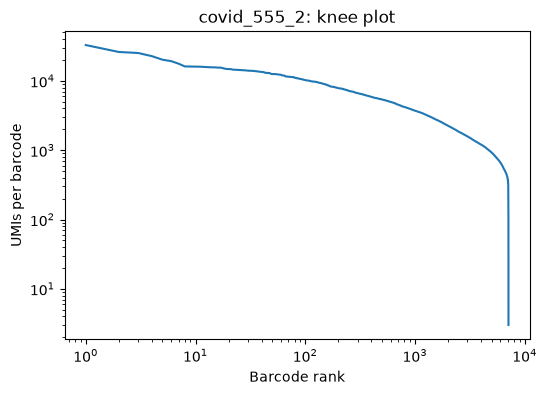

Barcodes with < 100 UMIs: 6
Barcodes with < 300 UMIs: 30
Barcodes with < 500 UMIs: 491
Barcodes with < 1000 UMIs: 2394


In [7]:
umis = np.sort(adata.obs["total_counts"].values)[::-1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(np.arange(1, len(umis) + 1), umis)
ax.set_xlabel("Barcode rank")
ax.set_ylabel("UMIs per barcode")
ax.set_title(f"{SAMPLE}: knee plot")
plt.show()

for cutoff in [100, 300, 500, 1000]:
    print(f"Barcodes with < {cutoff} UMIs: {(adata.obs['total_counts'] < cutoff).sum()}")

There is no clear bend and almost no empty-well tail. Seq-Well has no barcode whitelist, so `kb` built an allowlist from the data, and that step had already removed most empty-well barcodes (only 30 barcodes are under 300 UMIs). The knee plot therefore isn't useful as the main cell filter here, so cells are filtered on the per-cell metrics instead.

A side effect is that few empty barcodes are left, and ambient-RNA tools like SoupX estimate the background "soup" from them. Correcting for ambient RNA would need either rerunning `kb count -w NONE` to keep every barcode or a method that doesn't rely on empty barcodes.

## A5. QC metric distributions

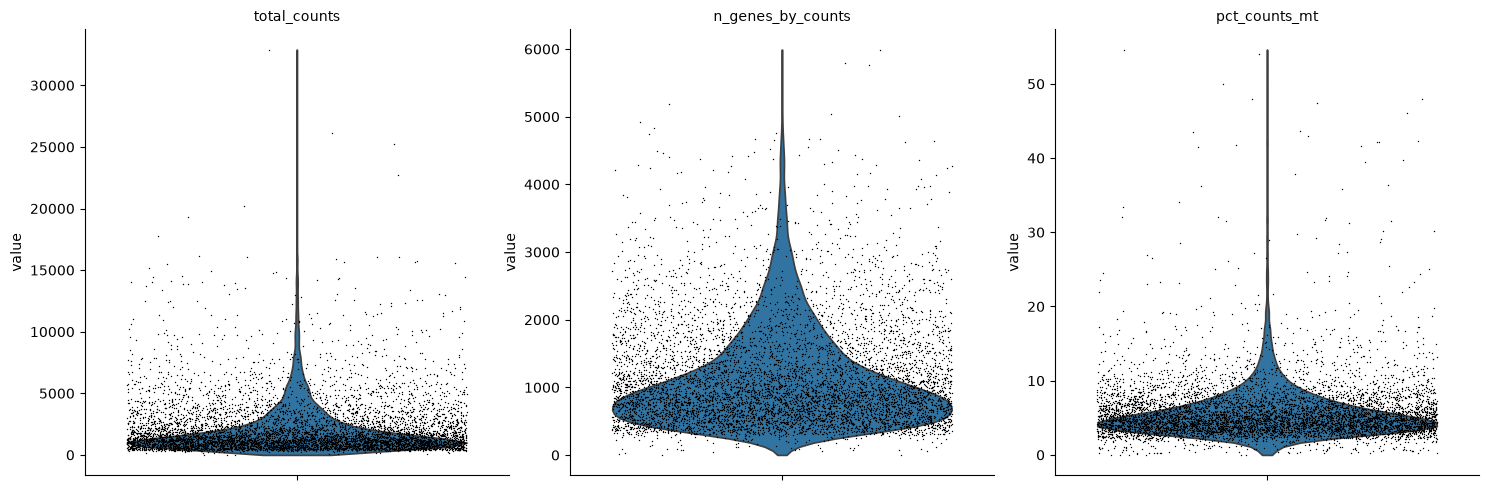

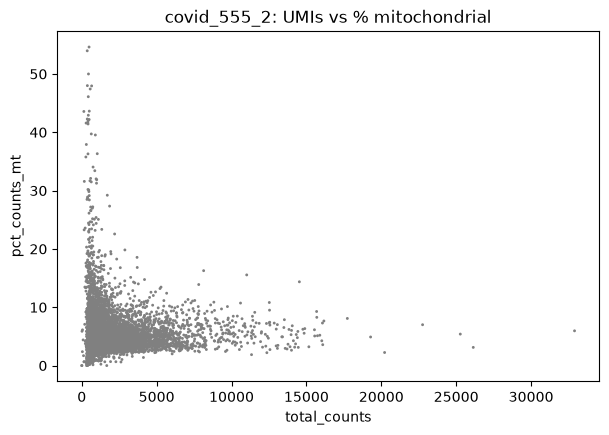

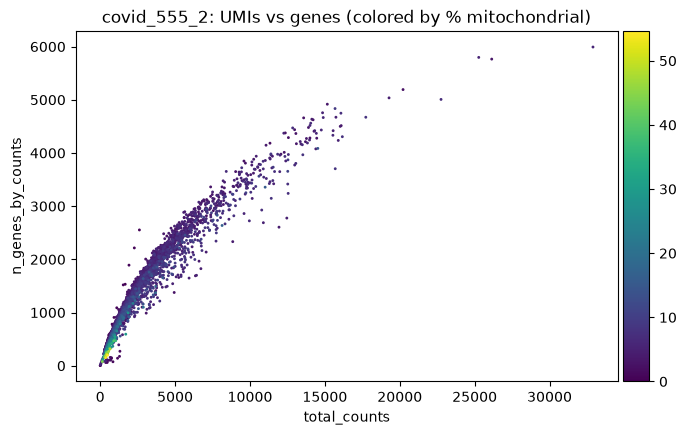

In [8]:
sc.pl.violin(adata, ["total_counts", "n_genes_by_counts", "pct_counts_mt"], jitter=0.4, multi_panel=True)
sc.pl.scatter(adata, x="total_counts", y="pct_counts_mt", title=f"{SAMPLE}: UMIs vs % mitochondrial")
sc.pl.scatter(adata, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt",
              title=f"{SAMPLE}: UMIs vs genes (colored by % mitochondrial)")

UMIs vs % mitochondrial forms an L shape. High-mitochondrial barcodes are almost all at **low UMIs**, consistent with damaged cells, while the rest sit around 3-10% mitochondrial at every UMI level. Genes rise smoothly with UMIs, and the few barcodes above 20,000 UMIs and 5,000+ genes are possible doublets.

## A6. Compare with the authors' counts

The authors processed the same reads with a different pipeline (STAR + dropEst on GRCh37). Comparing UMIs per cell on the shared barcodes checks whether both pipelines find the same cells, and gives a conversion factor for applying their QC cutoffs to these counts.

Barcodes in this pipeline               7106
Barcodes in the authors' matrix         9663
Barcodes in both                        7083
Spearman correlation (UMIs per cell)    0.980
Median ratio (this pipeline / authors)  0.90


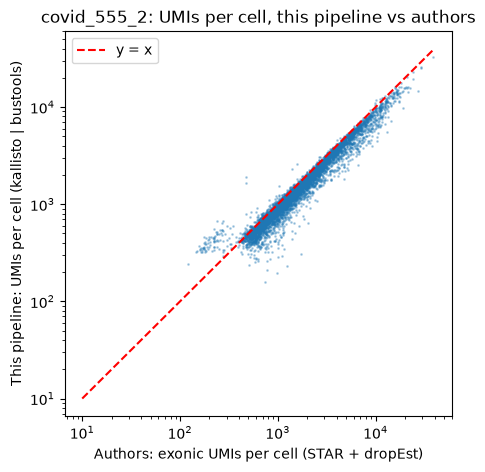

In [9]:
authors = pd.read_csv(f"{AUTHORS}/{SAMPLE}_authors_totals.csv", index_col="barcode")
merged  = adata.obs[["total_counts"]].join(authors, how="inner")

rho   = merged[["total_counts", "authors_exon"]].corr(method="spearman").iloc[0, 1]
ratio = (merged["total_counts"] / merged["authors_exon"]).median()

for label, value in [
    ("Barcodes in this pipeline", adata.n_obs),
    ("Barcodes in the authors' matrix", len(authors)),
    ("Barcodes in both", len(merged)),
    ("Spearman correlation (UMIs per cell)", f"{rho:.3f}"),
    ("Median ratio (this pipeline / authors)", f"{ratio:.2f}"),
]:
    print(f"{label:<40}{value}")

fig, ax = plt.subplots(figsize=(5, 5))
ax.loglog(merged["authors_exon"], merged["total_counts"], ".", markersize=2, alpha=0.3)
ax.plot([10, 40000], [10, 40000], "r--", label="y = x")
ax.set_xlabel("Authors: exonic UMIs per cell (STAR + dropEst)")
ax.set_ylabel("This pipeline: UMIs per cell (kallisto | bustools)")
ax.set_title(f"{SAMPLE}: UMIs per cell, this pipeline vs authors")
ax.legend()
plt.show()

7,083 of the 7,106 barcodes (99.7%) are also in the authors' matrix. Spearman ρ = 0.98, and per-cell UMIs are about 10% lower here than in theirs (ratio 0.90).

This is also consistent with the low pseudoalignment rate from the counting step (31.8% for this sample): 27.7% of the authors' UMIs are intronic, and the kallisto index here only has spliced transcripts, with the D-list rejecting intronic reads. So the low rate seems to come mostly from intronic reads rather than lost signal in the cells.

## A7. Cell filters

The paper's filters: 1,000-15,000 UMIs, ≤ 20% mitochondrial, cells with > 20% rRNA removed, and cells with > 75 genes per 100 UMIs removed (likely multiplets).

UMI cutoffs depend on the counting pipeline, so their numbers are multiplied by this sample's ratio to apply the same standard on this scale.

In [10]:
min_umi, max_umi, max_mt = 1000 * ratio, 15000 * ratio, 20

low_umi  = adata.obs["total_counts"] < min_umi
high_umi = adata.obs["total_counts"] > max_umi
high_mt  = adata.obs["pct_counts_mt"] > max_mt
fail     = low_umi | high_umi | high_mt   # a cell can fail more than one filter

print(f"Cutoffs on my scale: {min_umi:.0f}-{max_umi:.0f} UMIs, ≤ {max_mt}% MT")
print(f"Too few UMIs:   {low_umi.sum()}")
print(f"Too many UMIs:  {high_umi.sum()}")
print(f"Too much MT:    {high_mt.sum()}")
print(f"Pass all:       {(~fail).sum()} of {adata.n_obs}")

a = authors["authors_exon"]
print(f"Authors' barcodes passing their UMI filters: {((a >= 1000) & (a <= 15000)).sum()}")

Cutoffs on my scale: 903-13542 UMIs, ≤ 20% MT
Too few UMIs:   2036
Too many UMIs:  38
Too much MT:    78
Pass all:       5020 of 7106
Authors' barcodes passing their UMI filters: 5105


About 5,020 cells pass, close to the authors' 5,105 (their number is before their mitochondrial filter). The low-UMI cutoff removes the most barcodes, and most high-mitochondrial cells are also low-UMI, so the two filters overlap a lot.

## A8. Doublets (Scrublet)

Scrublet makes simulated doublets by adding together random pairs of real cells, then scores each real cell by how similar it is to them. `random_state` makes the result the same every run.

Predicted doublets: 0 of 5020 cells
Automatic threshold: 0.54


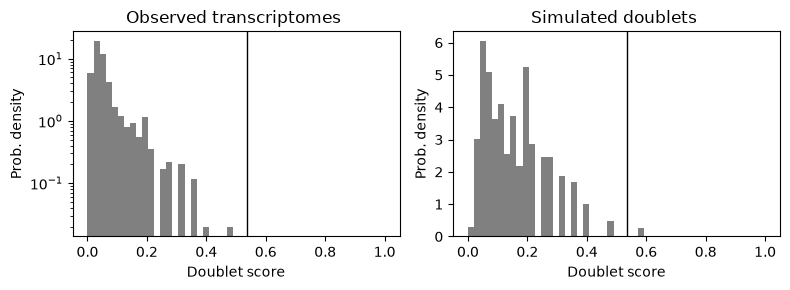

Doublet score > 0.2: 163
Doublet score > 0.25: 59
Doublet score > 0.3: 37


In [11]:
adata_f = adata[~fail].copy()   # .copy(): a separate object, not a view of `adata`
sc.pp.scrublet(adata_f, expected_doublet_rate=0.05, random_state=0)

print(f"Predicted doublets: {adata_f.obs['predicted_doublet'].sum()} of {adata_f.n_obs} cells")
threshold = adata_f.uns.get("scrublet", {}).get("threshold")
if threshold is not None:
    print(f"Automatic threshold: {threshold:.2f}")
sc.pl.scrublet_score_distribution(adata_f)

for t in [0.2, 0.25, 0.3]:
    print(f"Doublet score > {t}: {(adata_f.obs['doublet_score'] > t).sum()}")

Scrublet called 0 doublets: `predicted_doublet` is False for all 5,020 cells. In the plots, the vertical line is the automatic threshold, and every observed score (left) is below it. Simulated doublets usually form two peaks, a low one for doublets of similar cells and a high one for doublets of different cell types, with the threshold in the gap. Here they form one low peak (right plot), so the automatic threshold landed at 0.54, above every real cell's score. Shallow sequencing and many similar PBMC types may make doublets hard to separate in this data.

Scrublet's cutoff isn't applied. `doublet_score` is kept in `obs`, the upper UMI cap removes the largest barcodes, and doublets can be checked again after annotation using marker co-expression (e.g. CD3E + CD14) together with high scores.

## A9. rRNA check (the authors' other filter)

In [12]:
rrna = adata_f.var["gene_name"].str.match(r"^RNA(18|28|5-8|45)SN?\d")
print("rRNA genes in the annotation:", ", ".join(adata_f.var.loc[rrna, "gene_name"]))
print("rRNA UMIs across all cells:  ", int(adata_f[:, rrna].X.sum()))

rRNA genes in the annotation: RNA5-8SN3, RNA5-8SN1, RNA5-8SN2, RNA5-8SN4, RNA5-8SN5
rRNA UMIs across all cells:   0


The authors’ rRNA filter used RNA18S5 and RNA28S5, which aren’t in this annotation; only 5.8S rRNA genes are, and they have 0 UMIs. rRNA has no poly-A tail, so poly-T capture wouldn’t be expected to pick it up. The rRNA filter therefore isn’t needed for this data.

# Part B - All 13 samples

## B1. Load every sample

The Part A loading steps wrapped in one function. The `assert` repeats the gene-order check for every sample. Barcodes get the sample name as a prefix, since the 12-letter barcodes are random and the same one can appear in two samples.

In [13]:
samples = pd.read_csv("../assets/samplesheet.csv")

def load_sample(row):
    """Load one sample's kb count output and add gene names, QC metrics and sample information."""
    path = f"{RESULTS}/kb_count/{row['sample']}/counts_unfiltered/"
    ad = sc.read_h5ad(path + "adata.h5ad")

    # Gene names, with the order check
    ids   = pd.read_csv(path + "cells_x_genes.genes.txt",       header=None, skip_blank_lines=False)[0]
    names = pd.read_csv(path + "cells_x_genes.genes.names.txt", header=None, skip_blank_lines=False)[0]
    assert len(ids) == len(names) == ad.n_vars, f"Gene count mismatch in {row['sample']}"
    assert (ids.values == ad.var_names).all(),  f"Gene order mismatch in {row['sample']}"
    ad.var["gene_name"] = names.fillna(ids).values

    # QC metrics
    ad.var["mt"] = ad.var["gene_name"].str.startswith("MT-")
    sc.pp.calculate_qc_metrics(ad, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

    # Sample information on every cell
    for col in ["sample", "donor", "condition"]:
        ad.obs[col] = row[col]

    # Make barcodes unique across samples
    ad.obs_names = row["sample"] + "_" + ad.obs_names
    return ad

In [14]:
# A test on the sample already explored: should give 7,106 x 62,755
test = load_sample(samples[samples["sample"] == SAMPLE].iloc[0])
assert test.shape == adata.shape
print(test)

AnnData object with n_obs × n_vars = 7106 × 62755
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'donor', 'condition'
    var: 'gene_name', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'


In [15]:
adatas = {row["sample"]: load_sample(row) for _, row in samples.iterrows()}

summary = pd.DataFrame([
    {
        "sample":        s,
        "barcodes":      ad.n_obs,
        "median_umis":   ad.obs["total_counts"].median(),
        "median_genes":  ad.obs["n_genes_by_counts"].median(),
        "median_pct_mt": round(ad.obs["pct_counts_mt"].median(), 1),
        "virus_umis":    int(ad[:, ad.var["gene_name"] == "SARS-CoV-2"].X.sum()),
    }
    for s, ad in adatas.items()
]).set_index("sample")
summary

,barcodes,median_umis,median_genes,median_pct_mt,virus_umis
sample,,,,,
covid_555_1,12788,538.5,426.5,6.4,0
covid_555_2,7106,1343.0,922.0,4.9,0
covid_556,5135,660.0,502.0,6.7,0
covid_557,13039,1105.0,762.0,5.5,0
covid_558,15514,441.0,343.0,8.7,0
covid_559,4626,951.0,636.0,10.8,0
covid_561,6860,899.5,608.0,8.9,0
HIP002,7865,492.0,393.0,6.9,0
HIP015,3601,1458.0,900.0,8.3,0


- **SARS-CoV-2 UMIs = 0 in all 13 samples**, matching the paper ("No SARS-CoV-2 reads were aligned"), with the healthy donors as a negative control.
- Unfiltered medians aren't comparable between samples. Samples with more barcodes have lower medians (HIP045: 16,955 barcodes, median 340), since the extra low-count background barcodes pull the median down. This is why filtering is done per sample.

## B2. Per-sample QC

For each sample: compare with the authors' counts, convert their cutoffs with that sample's ratio, filter, and score doublets. Scrublet runs within each sample, since doublets can only form between cells on the same array.

In [16]:
results  = []
filtered = {}

for s, ad in adatas.items():
    # 1. Authors' totals, with barcodes renamed to match mine (sample_ prefix)
    auth = pd.read_csv(f"{AUTHORS}/{s}_authors_totals.csv", index_col="barcode")
    auth.index = s + "_" + auth.index

    # 2. Compare the two pipelines on shared barcodes
    m     = ad.obs[["total_counts"]].join(auth, how="inner")
    ratio = (m["total_counts"] / m["authors_exon"]).median()
    rho   = m[["total_counts", "authors_exon"]].corr(method="spearman").iloc[0, 1]

    # 3. The authors' cutoffs translated to this sample's scale
    min_umi, max_umi = 1000 * ratio, 15000 * ratio
    keep = ((ad.obs["total_counts"] >= min_umi) &
            (ad.obs["total_counts"] <= max_umi) &
            (ad.obs["pct_counts_mt"] <= 20))

    # 4. Keep passing cells; score doublets within this sample
    f = ad[keep].copy()
    sc.pp.scrublet(f, expected_doublet_rate=0.05, random_state=0)
    filtered[s] = f

    # 5. Record everything
    results.append({
        "sample":           s,
        "barcodes":         ad.n_obs,
        "matched":          len(m),
        "spearman":         round(rho, 3),
        "ratio":            round(ratio, 2),
        "min_umi":          round(min_umi),
        "max_umi":          round(max_umi),
        "cells_kept":       int(keep.sum()),
        "authors_umi_pass": int(((auth["authors_exon"] >= 1000) & (auth["authors_exon"] <= 15000)).sum()),
        "dbl_score_gt_025": int((f.obs["doublet_score"] > 0.25).sum()),
    })

qc_table = pd.DataFrame(results).set_index("sample")
qc_table

,barcodes,matched,spearman,ratio,min_umi,max_umi,cells_kept,authors_umi_pass,dbl_score_gt_025
sample,,,,,,,,,
covid_555_1,12788,12687,0.958,0.96,956,14338,3261,3490,46
covid_555_2,7106,7083,0.980,0.90,903,13542,5020,5105,59
covid_556,5135,5083,0.964,0.96,962,14425,1746,1829,12
covid_557,13039,12857,0.986,0.95,951,14264,7040,7211,109
covid_558,15514,15422,0.965,0.85,855,12823,3530,3794,63
covid_559,4626,4606,0.961,0.80,798,11972,2419,2698,52
covid_561,6860,6719,0.967,0.81,814,12205,3531,3809,11
HIP002,7865,7520,0.946,0.97,966,14485,2104,2268,48
HIP015,3601,3571,0.982,1.00,999,14978,2323,2357,56


Spearman is 0.946-0.989 for every sample and the ratios range from 0.80 to 1.00, so one cutoff for all samples wouldn't fit (the low-UMI cutoff is 798 for covid_559 and 999 for HIP015). Cells kept are 88-99% of the authors' UMI-filter count. **46,431 cells pass** (COVID 26,547; healthy 19,884), compared with 48,829 using the authors' UMI filter.

Barcode overlap with the authors is 96-99% for every sample except HIP045 (13,687 of 16,955, about 81%). HIP045 also has the most barcodes, so the extra ones are likely low-count background barcodes that the authors didn't keep. After filtering it keeps 88% of the authors' cell count, similar to other samples, so it stays in.

## B3. Combine, filter genes, save

- Cell filters are applied per sample, since each sample has its own quality. The gene filter is applied after combining, since a gene that is rare in one sample can still be common overall.
- Raw counts are copied into `layers["counts"]` before normalizing, since pseudobulk and scVI need raw counts later.

In [17]:
adata_all = sc.concat(list(filtered.values()), merge="same")   # merge="same": keep var columns identical across samples
print(adata_all)
display(adata_all.obs["condition"].value_counts().rename_axis("condition").to_frame("cells"))

n_before = adata_all.n_vars
sc.pp.filter_genes(adata_all, min_cells=10)   # the authors' rule: genes detected in fewer than 10 cells removed
print(f"Genes before filtering: {n_before}")
print(f"Genes after filtering:  {adata_all.n_vars} (detected in at least 10 cells)")

adata_all.layers["counts"] = adata_all.X.copy()

AnnData object with n_obs × n_vars = 46431 × 62755
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'sample', 'donor', 'condition', 'doublet_score', 'predicted_doublet'
    var: 'gene_name', 'mt'


,cells
condition,
COVID,26547
Healthy,19884


Genes before filtering: 62755
Genes after filtering:  40448 (detected in at least 10 cells)


In [18]:
os.makedirs(f"{RESULTS}/qc", exist_ok=True)
qc_table.to_csv(f"{RESULTS}/qc/qc_summary.csv")
adata_all.write_h5ad(f"{RESULTS}/qc/combined_qc.h5ad")

The per-sample cutoffs are saved to `assets/qc_cutoffs.csv`, so the pipeline can apply them without the authors' files.

In [19]:
# Cutoffs chosen here, used by the pipeline's QC step
cutoffs = qc_table[["min_umi", "max_umi"]].copy()
cutoffs["max_pct_mt"] = 20
cutoffs.to_csv("../assets/qc_cutoffs.csv")
cutoffs

,min_umi,max_umi,max_pct_mt
sample,,,
covid_555_1,956,14338,20
covid_555_2,903,13542,20
covid_556,962,14425,20
covid_557,951,14264,20
covid_558,855,12823,20
covid_559,798,11972,20
covid_561,814,12205,20
HIP002,966,14485,20
HIP015,999,14978,20


## Summary

46,431 cells from 13 libraries (COVID 26,547; healthy 19,884) and 40,448 genes pass QC. The counts agree closely with the authors' (99.7% of barcodes shared for covid_555_2, per-cell Spearman 0.95-0.99, no SARS-CoV-2 reads), and their cutoffs were applied after scaling to these counts per sample. Scrublet didn't flag doublets and ambient RNA isn't corrected, so both come up again after clustering.